# UTS Metode Kecerdasan Buatan Lanjut
**Nama:** M Zainur Rahman Al Faiqi  
**NIM:** 2411003  
**Prodi:** Informatika 24  
**Pilihan:** Saya memilih Opsi 3 — Autoencoder: Rekonstruksi dan Kompresi Gambar

Notebook ini mengikuti langkah pada dokumen UTS: MNIST, PCA 32 komponen sebagai baseline, Autoencoder dengan bottleneck 32 dimensi, perbandingan MSE, dan visualisasi rekonstruksi.

## BAGIAN A

### A1 — Transfer Learning
Pendapat Budi lebih tepat jika data target terbatas dan tugasnya cukup mirip dengan data ImageNet. Cara Budi disebut **feature extraction**: model **pretrained** digunakan untuk mengambil fitur, layer dasarnya dibekukan (*freezing layer*), lalu layer klasifikasi baru dilatih. Pendapat Ani, yaitu melatih seluruh layer dari awal tanpa memanfaatkan bobot pretrained, disebut **training from scratch**, bukan *fine-tuning*. Jika kita tetap memakai bobot pretrained lalu membuka dan melatih sebagian atau seluruh layer agar menyesuaikan dataset baru, teknik itu disebut **fine-tuning**. Feature extraction cocok saat data sedikit, sedangkan fine-tuning dapat dipilih saat data target lebih banyak atau domainnya cukup berbeda; training from scratch umumnya membutuhkan data dan komputasi lebih besar.

### A2 — RNN dan LSTM
Deret suhu harian termasuk **data sekuensial**, karena urutan dan hubungan waktu antarobservasi memiliki makna. LSTM lebih cocok daripada RNN vanilla karena mekanisme *cell state* dan gerbangnya membantu mempertahankan informasi jangka panjang serta mengurangi masalah *vanishing gradient*, sehingga informasi dari hari-hari sebelumnya lebih mungkin dimanfaatkan. Perbedaan mendasar LSTM dan GRU adalah LSTM memiliki *cell state* terpisah serta tiga gerbang utama, sedangkan GRU menggabungkan mekanisme memorinya dalam struktur yang lebih sederhana dengan dua gerbang.

### A3 — Autoencoder
Vektor 32 angka disebut **bottleneck/latent representation** yang berada dalam *latent space*; fungsinya memadatkan informasi penting gambar agar decoder dapat merekonstruksinya. Autoencoder bersifat **unsupervised** karena target pelatihannya adalah gambar masukan itu sendiri, bukan label kelas seperti “kucing” atau “anjing”. Jika gambar sangat berbeda dari pola yang dipelajari, hasil rekonstruksinya dapat memiliki **reconstruction error** lebih tinggi; error tersebut dapat digunakan sebagai sinyal **deteksi anomali**, meskipun ambang anomali perlu ditentukan dan diuji.

## BAGIAN B — Implementasi Opsi 3: Autoencoder MNIST

### Langkah 1 — Persiapan data
Data MNIST disediakan oleh Keras dan sudah memiliki pembagian bawaan: 60.000 gambar training dan 10.000 gambar testing. Label sengaja diabaikan karena autoencoder belajar merekonstruksi input, bukan memprediksi kelas angka.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape X_train: (60000, 784)
Shape X_test : (10000, 784)


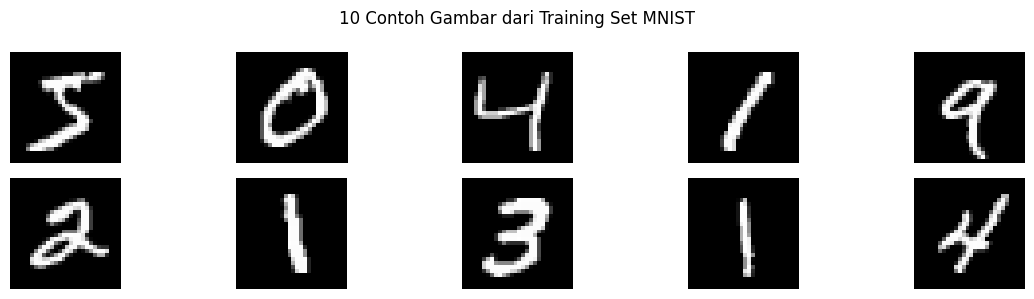

In [ ]:
# Memuat library dan dataset MNIST sesuai instruksi soal.
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Memuat gambar; label tidak digunakan dalam pelatihan autoencoder.
(X_train_img, _), (X_test_img, _) = mnist.load_data()

# Normalisasi piksel ke rentang 0 sampai 1.
X_train_img = X_train_img.astype("float32") / 255.0
X_test_img = X_test_img.astype("float32") / 255.0

# Flatten gambar 28x28 menjadi vektor 784 fitur.
X_train = X_train_img.reshape((len(X_train_img), 784))
X_test = X_test_img.reshape((len(X_test_img), 784))

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

# Menampilkan 10 contoh gambar dari training set (gambar, bukan angka).
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_img[i], cmap="gray")
    plt.axis("off")
plt.suptitle("10 Contoh Gambar dari Training Set MNIST")
plt.tight_layout()
plt.show()

In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)

Jumlah data training: 60000
Jumlah data testing: 10000
Shape X_train: (60000, 784)
Shape X_test: (10000, 784)


In [ ]:
import numpy as np

# Normalisasi pixel dari 0–255 menjadi 0–1
X_train = X_train_img.astype("float32") / 255.0
X_test = X_test_img.astype("float32") / 255.0

# Flatten gambar 28x28 menjadi 784 fitur
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# Periksa hasil preprocessing
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 784)
X_test: (10000, 784)


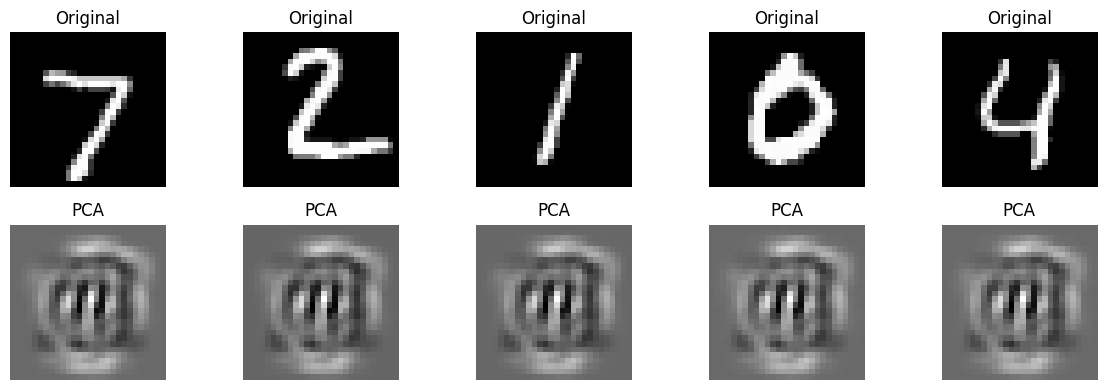

In [ ]:
#Hasil Rekrontuksi PCA
import matplotlib.pyplot as plt

X_pca = pca.inverse_transform(pca.transform(X_test))

plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(X_pca[i].reshape(28, 28), cmap="gray")
    plt.title("PCA")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Langkah 2 — Model baseline PCA
PCA mereduksi 784 dimensi menjadi 32 komponen, kemudian `inverse_transform` mengembalikan representasi ke 784 dimensi untuk dibandingkan.

MSE rekonstruksi PCA: 0.016828


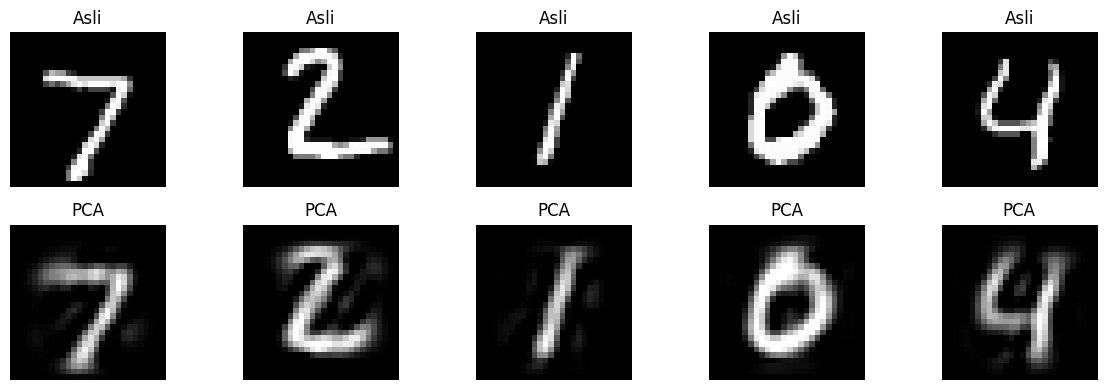

In [ ]:
# Membuat baseline PCA dengan 32 komponen.
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

pca = PCA(n_components=32, random_state=42)
X_train_pca = pca.fit_transform(X_train)

# Rekonstruksi data uji menggunakan PCA yang dipelajari dari data train.
X_test_reconstructed_pca = pca.inverse_transform(pca.transform(X_test))
mse_pca = mean_squared_error(X_test, X_test_reconstructed_pca)

print(f"MSE rekonstruksi PCA: {mse_pca:.6f}")

# Menampilkan lima gambar asli dan hasil rekonstruksi PCA.
plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title("Asli")
    plt.axis("off")
    plt.subplot(2, 5, i + 6)
    plt.imshow(np.clip(X_test_reconstructed_pca[i].reshape(28, 28), 0, 1), cmap="gray")
    plt.title("PCA")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Langkah 3 — Membangun dan melatih Autoencoder
Arsitektur mengikuti soal: 784 → 128 → 32 → 128 → 784. Output menggunakan sigmoid agar nilai rekonstruksi berada pada rentang 0–1.

In [ ]:
# Membangun arsitektur encoder-decoder sesuai susunan yang ditentukan.
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

input_layer = Input(shape=(784,))
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)  # bottleneck 32 dimensi
decoded = Dense(128, activation="relu")(encoded)
output_layer = Dense(784, activation="sigmoid")(decoded)

autoencoder = Model(input_layer, output_layer)
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

# Melatih dengan input sekaligus target berupa gambar yang sama.
start_time = time.time()
history = autoencoder.fit(
    X_train, X_train,
    epochs=30,
    batch_size=256,
    validation_data=(X_test, X_test),
    verbose=1
)
autoencoder_training_seconds = time.time() - start_time

# Merekonstruksi seluruh data uji dan menghitung MSE.
X_reconstructed = autoencoder.predict(X_test, verbose=0)
mse_autoencoder = mean_squared_error(X_test, X_reconstructed)

print(f"MSE rekonstruksi Autoencoder: {mse_autoencoder:.6f}")
print(f"Waktu training Autoencoder: {autoencoder_training_seconds:.2f} detik")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0610 - val_loss: 0.0335
Epoch 2/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0271 - val_loss: 0.0216
Epoch 3/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0200 - val_loss: 0.0177
Epoch 4/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.0170 - val_loss: 0.0154
Epoch 5/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0153 - val_loss: 0.0143
Epoch 6/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0143 - val_loss: 0.0134
Epoch 7/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0136 - val_loss: 0.0129
Epoch 8/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0130 - val_loss: 0.0124
Epoch 9/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0126 - val_loss: 0.0120
Epoch 10/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0122 - val_loss: 0.0117
Epoch 11/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0119 - val_loss: 0.0114
Epoch 12/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 

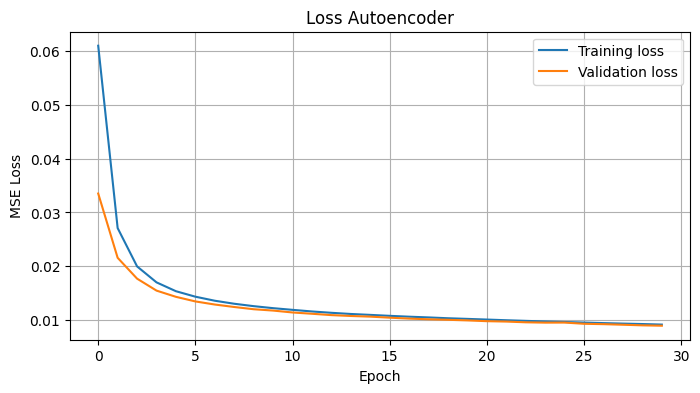

In [ ]:
# Menampilkan loss training dan validation selama 30 epoch.
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Loss Autoencoder")
plt.legend()
plt.grid(True)
plt.show()

### Langkah 4 — Perbandingan dan visualisasi
Nilai MSE yang lebih kecil menunjukkan rata-rata kesalahan rekonstruksi yang lebih rendah pada data uji. Penilaian visual tetap diperlukan karena angka MSE tidak sepenuhnya menggambarkan ketajaman atau bentuk digit.

,Metode,Dimensi Asli,Dimensi Kompresi,MSE Rekonstruksi
0,PCA,784,32,0.016828
1,Autoencoder,784,32,0.008911


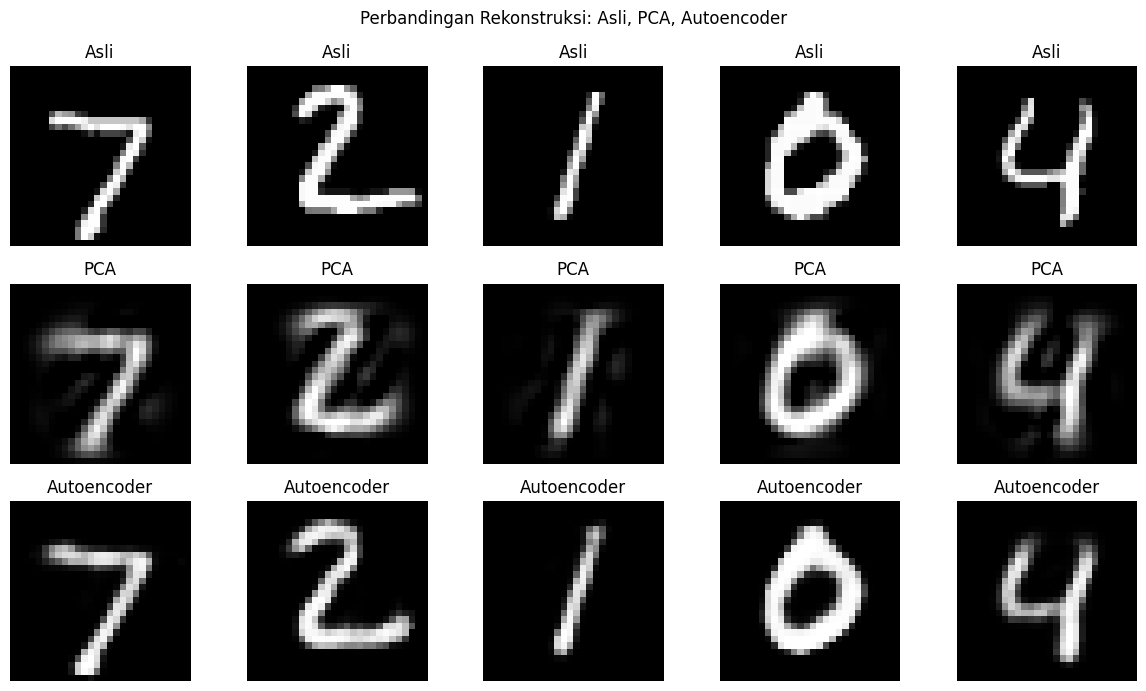

Autoencoder menghasilkan MSE lebih rendah daripada PCA pada data uji.
MSE PCA: 0.016828
MSE Autoencoder: 0.008911


In [ ]:
# Membuat tabel perbandingan PCA dan Autoencoder.
import pandas as pd

comparison = pd.DataFrame({
    "Metode": ["PCA", "Autoencoder"],
    "Dimensi Asli": [784, 784],
    "Dimensi Kompresi": [32, 32],
    "MSE Rekonstruksi": [mse_pca, mse_autoencoder]
})
display(comparison)

# Membandingkan lima gambar uji yang sama dalam tiga baris.
plt.figure(figsize=(12, 7))
for i in range(5):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title("Asli")
    plt.axis("off")

    plt.subplot(3, 5, i + 6)
    plt.imshow(np.clip(X_test_reconstructed_pca[i].reshape(28, 28), 0, 1), cmap="gray")
    plt.title("PCA")
    plt.axis("off")

    plt.subplot(3, 5, i + 11)
    plt.imshow(X_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Autoencoder")
    plt.axis("off")

plt.suptitle("Perbandingan Rekonstruksi: Asli, PCA, Autoencoder")
plt.tight_layout()
plt.show()

# Menyusun kesimpulan otomatis berdasarkan MSE yang benar-benar dihitung.
if mse_autoencoder < mse_pca:
    print("Autoencoder menghasilkan MSE lebih rendah daripada PCA pada data uji.")
else:
    print("PCA menghasilkan MSE lebih rendah atau sama dengan Autoencoder pada data uji.")
print("MSE PCA:", round(mse_pca, 6))
print("MSE Autoencoder:", round(mse_autoencoder, 6))

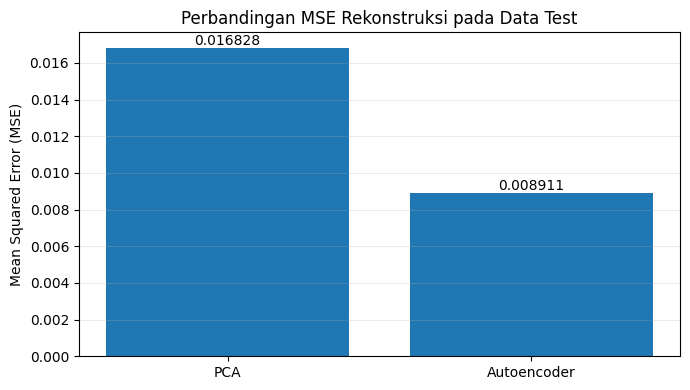

In [ ]:
# Membuat grafik batang MSE PCA dan Autoencoder agar hasil numerik mudah dibandingkan.
metode = ["PCA", "Autoencoder"]
nilai_mse = [mse_pca, mse_autoencoder]

plt.figure(figsize=(7, 4))
bars = plt.bar(metode, nilai_mse)
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Perbandingan MSE Rekonstruksi pada Data Test")
plt.grid(axis="y", alpha=0.25)
for bar, nilai in zip(bars, nilai_mse):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{nilai:.6f}",
             ha="center", va="bottom")
plt.tight_layout()
plt.show()


### Analisis hasil



1\. Berdasarkan tabel, Autoencoder menghasilkan MSE lebih rendah, yaitu 0.008911, sedangkan PCA memiliki MSE sebesar 0.016828.

2\. Secara visual, rekonstruksi PCA terlihat lebih jelas pada bagian bentuk dan garis beberapa digit.

3\. Hasil visual tersebut tidak sepenuhnya sesuai dengan nilai MSE karena PCA tampak lebih jelas pada beberapa gambar, meskipun nilai kesalahan rekonstruksinya lebih tinggi.

4\. Autoencoder memiliki kelebihan karena mampu mempelajari hubungan nonlinier melalui jaringan neural, sedangkan PCA hanya melakukan transformasi linier.




## BAGIAN C — REFLEKSI

### C1 — Apa yang Saya Pelajari?

Hal yang paling saya pahami setelah mengerjakan UTS ini adalah konsep reduksi dimensi menggunakan PCA dan Autoencoder. Hal tersebut saya lihat ketika gambar MNIST yang awalnya memiliki 784 dimensi dikompresi menjadi 32 dimensi, kemudian direkonstruksi kembali menjadi gambar. Namun, hal yang masih membingungkan bagi saya adalah bagaimana Autoencoder mempelajari pola dan hubungan nonlinier selama proses pelatihan. Menurut saya, belajar AI berguna untuk membantu manusia menyelesaikan pekerjaan dengan lebih cepat dan efisien, contohnya teknologi pengenalan wajah pada smartphone.

### C2 — Proses Pengerjaan saya

1. Bagian paling sulit: Memahami perbedaan hasil rekonstruksi PCA dan Autoencoder serta membandingkan nilai MSE dengan tampilan visual.
2. Cara mengatasi kesulitan: Membandingkan nilai MSE dan mengamati hasil rekonstruksi menggunakan lima gambar uji yang sama.
3. Total waktu pengerjaan: empat hari.
4. Eksperimen tambahan: Saya ingin mencoba mengubah ukuran bottleneck dari 32 menjadi 64 dimensi untuk mengetahui pengaruhnya terhadap kualitas rekonstruksi gambar dan nilai MSE.
